<a href="https://colab.research.google.com/github/flavio-mota/topicos-em-ia/blob/main/Semin%C3%A1rio_de_Frameworks_de_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Seminário: Scikit-learn, PyTorch e Optuna

**Autor:** Flávio Mota  
**Disciplina:** Tópicos em Inteligência Artificial e Otimização I, PPGCC/UFLA

## Para que serve este notebook

Este notebook é a demonstração prática do seminário sobre frameworks de Inteligência Artificial. Os slides apresentam o que é cada ferramenta; aqui elas são usadas, uma após a outra, para resolver um mesmo problema do início ao fim.

A ideia é mostrar o caminho completo de um projeto de aprendizado de máquina: preparar os dados, criar um modelo de referência, treinar uma rede neural e otimizar seus hiperparâmetros, validando cada etapa. Cada ferramenta entra para superar uma limitação da anterior.

## O problema

Prever o **tipo de floresta** que cobre uma área de 30 × 30 metros a partir de dados cartográficos, como altitude, inclinação do terreno, distância até cursos d'água e tipo de solo. É um problema de **classificação** com 7 classes.

Os dados são da base pública **Covertype**, com 581.012 áreas da Floresta Nacional Roosevelt, no Colorado (EUA), e 54 atributos. Ela foi escolhida por três motivos:

- é uma tabela, com atributos fáceis de entender;
- um modelo linear não resolve bem o problema, o que dá espaço para a rede neural e para a otimização;
- as classes são desbalanceadas, o que obriga a ler a acurácia com cuidado.

Fonte: Blackard, J. A.; Dean, D. J. (1999). *Comparative accuracies of artificial neural networks and discriminant analysis in predicting forest cover types from cartographic variables*. Computers and Electronics in Agriculture, 24(3), 131–151. Disponível no [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/31/covertype) e no Scikit-learn (`fetch_covtype`).

## Roteiro

| Seção | Ferramenta | O que é feito |
| --- | --- | --- |
| 0 | pandas | Carregar e conhecer os dados |
| 1 | Scikit-learn | Escolher um modelo com o guia da biblioteca, preparar os dados e criar a referência |
| 2 | PyTorch | Construir uma rede neural e escrever o loop de treino |
| 3 | Optuna | Otimizar os hiperparâmetros da rede |
| 4 | Todas | Comparar os modelos no conjunto de teste |

## Como executar

Vamos instalar as dependências: `pip install scikit-learn torch optuna pandas matplotlib`

In [ ]:
!pip install scikit-learn torch optuna pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.4 MB/s eta 0:00:00


A célula a seguir importa os módulos necessários para essa prática e faz algumas configurações, como a definição de um valor para a semente aleatória (o que permite reprodutibilidade dos experimentos):

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

import optuna
from sklearn.datasets import fetch_covtype
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

SEMENTE = 42
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

A célula a seguir permite que os arquivos gerados, importantes para a etapa do Optuna, sejam salvos no Drive quando o notebook é rodado no ambiente do Google Colab.

In [ ]:
import os
import shutil

ARQUIVO_DB = "estudo_seminario.db"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_DRIVE = "/content/drive/MyDrive/seminario_frameworks_ia"
    os.makedirs(PASTA_DRIVE, exist_ok=True)
except ImportError:
    PASTA_DRIVE = None      # fora do Colab: o arquivo fica só na pasta local


def restaurar_estudo():
    """Traz o estudo do Drive para o disco local, se houver uma cópia lá."""
    if PASTA_DRIVE is None:
        return
    origem = os.path.join(PASTA_DRIVE, ARQUIVO_DB)
    if os.path.exists(origem):
        shutil.copy2(origem, ARQUIVO_DB)
        print("Estudo restaurado do Drive.")
    else:
        print("Nenhum estudo no Drive: será criado um novo.")


def salvar_estudo():
    """Copia o estudo do disco local para o Drive."""
    if PASTA_DRIVE is not None and os.path.exists(ARQUIVO_DB):
        shutil.copy2(ARQUIVO_DB, os.path.join(PASTA_DRIVE, ARQUIVO_DB))

Mounted at /content/drive


## Os dados

Carregamos a base e tiramos uma amostra estratificada de 20.000 linhas, para que cada treino leve alguns segundos. Dos 54 atributos, 10 são numéricos (altitude, inclinação, distâncias, sombreamento) e 44 são colunas 0/1 (área de preservação e tipo de solo). Na saída da célula, são exibidos apenas alguns exemplos dos atributos e amostras.

In [ ]:
dados = fetch_covtype(as_frame=True)

CLASSES = ["Spruce/Fir", "Lodgepole Pine", "Ponderosa Pine", "Cottonwood/Willow",
           "Aspen", "Douglas-fir", "Krummholz"]

# Amostra estratificada: mantém a proporção de cada classe.
X, _, y, _ = train_test_split(
    dados.data, dados.target - 1,          # classes de 0 a 6
    train_size=20_000, stratify=dados.target, random_state=SEMENTE,
)

print(X.shape)
X.iloc[:5, :12]

(20000, 54)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1
363761,2879.0,7.0,8.0,810.0,84.0,2230.0,211.0,225.0,151.0,949.0,0.0,0.0
564387,2630.0,5.0,23.0,42.0,9.0,1511.0,184.0,190.0,137.0,2021.0,0.0,0.0
76466,2856.0,46.0,13.0,228.0,40.0,3336.0,224.0,211.0,119.0,2940.0,1.0,0.0
285711,2959.0,311.0,10.0,443.0,44.0,2900.0,194.0,233.0,179.0,1485.0,0.0,0.0
262274,2309.0,162.0,4.0,127.0,46.0,1019.0,223.0,240.0,152.0,860.0,0.0,0.0


Os atributos têm escalas muito diferentes. Isso justifica a padronização no próximo bloco (ao preparar o Pipeline da scikit).

In [ ]:
X.iloc[:, :10].describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
Elevation,2958.8,279.4,1876.0,3856.0
Aspect,155.8,111.8,0.0,360.0
Slope,14.1,7.5,0.0,51.0
Horizontal_Distance_To_Hydrology,270.4,213.7,0.0,1397.0
Vertical_Distance_To_Hydrology,46.9,58.9,-152.0,550.0
Horizontal_Distance_To_Roadways,2349.7,1555.0,0.0,7039.0
Hillshade_9am,212.1,27.0,0.0,254.0
Hillshade_Noon,223.3,19.6,87.0,254.0
Hillshade_3pm,142.6,38.3,0.0,252.0
Horizontal_Distance_To_Fire_Points,1986.8,1327.9,0.0,7141.0


Além disso, as classes são desbalanceadas: as duas mais comuns somam cerca de 85% dos registros.

In [ ]:
contagem = y.value_counts().sort_index()
pd.DataFrame({
    "classe": CLASSES,
    "linhas": contagem.values,
    "proporção (%)": (100 * contagem / len(y)).round(1).values,
})

,classe,linhas,proporção (%)
0,Spruce/Fir,7292,36.5
1,Lodgepole Pine,9752,48.8
2,Ponderosa Pine,1231,6.2
3,Cottonwood/Willow,94,0.5
4,Aspen,327,1.6
5,Douglas-fir,598,3.0
6,Krummholz,706,3.5


---
## 1. Scikit-learn: escolher um modelo, preparar os dados e criar a referência

### 1.1 O guia de escolha do estimador

A documentação do Scikit-learn traz o fluxograma [Choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html). O caminho do nosso problema:

1. Mais de 50 amostras? **Sim.**
2. Prever uma categoria? **Sim.**
3. Os dados são rotulados? **Sim**, então é classificação.
4. Menos de 100 mil amostras? **Sim** (20.000), então o ponto de partida é o `LinearSVC`.

Com a base inteira (581 mil linhas), o guia indicaria o `SGDClassifier`.

### 1.2 Divisão em treino, validação e teste

60% para treino, 20% para validação e 20% para teste, com `stratify` para manter a proporção das classes. O conjunto de teste só volta a aparecer na última seção, quando formos comparar os métodos utilizados.

In [ ]:
X_tv, X_teste, y_tv, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_tv, y_tv, test_size=0.25, stratify=y_tv, random_state=SEMENTE)

print(f"treino: {len(X_treino)} | validação: {len(X_val)} | teste: {len(X_teste)}")

treino: 12000 | validação: 4000 | teste: 4000


### 1.3 O piso: prever sempre a classe mais comum

Antes de treinar qualquer modelo, vale responder a uma pergunta: **qual acurácia se consegue sem aprender nada?**

A acurácia é a proporção de previsões corretas. Com 7 classes do mesmo tamanho, um chute acertaria cerca de 14% das vezes, e qualquer resultado acima disso já indicaria algum aprendizado. Mas as classes desta base são desbalanceadas: só a *Lodgepole Pine* responde por quase metade das linhas. Um "modelo" que ignore todos os atributos e responda sempre *Lodgepole Pine* acerta perto de 49% das vezes.

Esse valor é o **piso** do problema, e ele muda a leitura de todos os resultados seguintes:

- uma acurácia de 50% parece razoável para 7 classes, mas aqui equivale a não ter aprendido nada;
- o ganho real de um modelo é a distância até o piso, não até zero;
- se um modelo ficar preso exatamente nesse valor, é sinal de que ele passou a prever só a classe mais comum. Isso vai acontecer na seção 2.5, com uma taxa de aprendizado mal escolhida.

O Scikit-learn tem um estimador próprio para isso, o `DummyClassifier`. Com `strategy="most_frequent"`, ele memoriza a classe mais comum do treino e a repete para qualquer entrada. Como segue a mesma interface dos outros modelos (`fit`, `predict`, `score`), pode ser avaliado e comparado exatamente da mesma forma.

In [ ]:
piso = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

acc_piso_val = piso.score(X_val, y_val)
print(f"Classe mais comum | acurácia de validação: {acc_piso_val:.3f}")

Classe mais comum | acurácia de validação: 0.487


### 1.4 Pipeline e validação cruzada

Esta célula monta o modelo de referência e mede seu desempenho. Ela reúne duas ideias centrais do Scikit-learn.

**Pipeline: pré-processamento e modelo como um objeto só**

O `LinearSVC`, indicado pelo guia, é sensível à escala dos atributos. Nesta base, a altitude está na casa dos milhares de metros e convive com colunas que só valem 0 ou 1; sem tratamento, os atributos de valores maiores dominariam o modelo. O `StandardScaler` resolve isso, deixando cada atributo com média 0 e desvio padrão 1.

O `Pipeline` encadeia as duas etapas. Ao chamar `fit`, ele ajusta o `StandardScaler`, transforma os dados e treina o `LinearSVC`. Ao chamar `predict`, aplica a mesma transformação antes de prever. Para o restante do código, o conjunto se comporta como um único modelo.

**Validação cruzada: uma medida mais confiável**

Avaliar o modelo em uma única divisão dos dados dá um número que depende de quais linhas caíram em cada lado. A validação cruzada reduz essa dependência: o `cross_val_score` divide o conjunto de treino em 5 partições e repete o processo 5 vezes, treinando com 4 delas (9.600 linhas) e avaliando na que ficou de fora (2.400 linhas). O resultado são 5 acurácias, resumidas pela média. A diferença entre elas mostra o quanto o resultado varia de uma divisão para outra.

Para classificadores, o Scikit-learn faz essa divisão de forma estratificada, mantendo a proporção das classes em cada partição.

**Por que o `StandardScaler` fica dentro do `Pipeline`**

A média e o desvio padrão usados na padronização são calculados a partir dos dados. Se o `StandardScaler` fosse ajustado uma única vez, com todo o conjunto de treino, antes da validação cruzada, as estatísticas incluiriam as linhas que depois servem para avaliar o modelo. Isso é **vazamento de dados**: informação da validação participa do treino, e a acurácia medida fica otimista.

Com o `StandardScaler` dentro do `Pipeline`, o `cross_val_score` refaz o ajuste em cada rodada, usando apenas as 4 partições de treino daquela rodada. A partição de validação é tratada como dado realmente novo, que é a situação em que o modelo será usado.

In [ ]:
modelo_svc = Pipeline([
    ("escala", StandardScaler()),
    ("svc", LinearSVC(random_state=SEMENTE, max_iter=10_000)),
])

notas = cross_val_score(modelo_svc, X_treino, y_treino, cv=5, scoring="accuracy")
print("Acurácia em cada partição:", notas.round(3))
print(f"Acurácia média: {notas.mean():.3f}")

Acurácia em cada partição: [0.725 0.724 0.703 0.717 0.705]
Acurácia média: 0.715


### 1.5 Busca em grade

O `GridSearchCV` testa todas as combinações da grade com validação cruzada. Aqui há um único hiperparâmetro, o `C` do `LinearSVC`, que controla a regularização. Nesta base o ganho é pequeno: o objetivo é mostrar o mecanismo.

In [ ]:
busca = GridSearchCV(
    modelo_svc,
    {"svc__C": [0.01, 0.1, 1, 10]},
    cv=5,
    scoring="accuracy",
)
busca.fit(X_treino, y_treino)

pd.DataFrame(busca.cv_results_)[["param_svc__C", "mean_test_score"]].round(4)

,param_svc__C,mean_test_score
0,0.01,0.7108
1,0.10,0.7148
2,1.00,0.7146
3,10.00,0.7152


In [ ]:
modelo_svc = busca.best_estimator_      # já treinado com todo o conjunto de treino

acc_svc_val = modelo_svc.score(X_val, y_val)
print("Melhor C:", busca.best_params_["svc__C"])
print(f"LinearSVC | acurácia de validação: {acc_svc_val:.3f}")

Melhor C: 10
LinearSVC | acurácia de validação: 0.717


---
## 2. PyTorch: uma rede neural com o treino escrito à mão

O modelo linear chegou a cerca de 72% de acurácia. O guia do Scikit-learn ainda sugere outros modelos para tentar, mas nenhum deles é uma rede neural, e a biblioteca não foi feita para isso (apesar de incluir um MLP). Para definir a arquitetura e controlar o treino, uma ferramenta que pode ser utilizada é o PyTorch.

Nesta seção, os dados são convertidos para o formato do PyTorch, a rede é definida como uma classe e o treino é escrito passo a passo. Ao final, a rede é comparada com o modelo de referência.

### 2.1 Dos arrays aos tensores

O PyTorch trabalha com **tensores**, que são arrays como os do NumPy, com suporte a GPU e ao cálculo automático de gradientes. A divisão em treino, validação e teste e a padronização continuam vindo do Scikit-learn; aqui os dados já preparados são apenas convertidos.

Dois detalhes do código: o `StandardScaler` é ajustado só com o treino e depois aplicado aos três conjuntos, e os tipos seguem o que o PyTorch espera, com atributos em `float32` e classes em inteiros (`long`).

In [ ]:
escala = StandardScaler().fit(X_treino)

def para_tensores(X, y):
    X_t = torch.tensor(escala.transform(X), dtype=torch.float32)
    y_t = torch.tensor(y.to_numpy(), dtype=torch.long)
    return X_t, y_t

Xt_treino, yt_treino = para_tensores(X_treino, y_treino)
Xt_val, yt_val = para_tensores(X_val, y_val)
Xt_teste, yt_teste = para_tensores(X_teste, y_teste)

Xt_treino.shape, yt_treino.shape

(torch.Size([12000, 54]), torch.Size([12000]))

### 2.2 A rede: um `nn.Module`

No PyTorch, toda rede neural é uma classe que herda de `nn.Module`. Ela tem duas partes:

- `__init__` declara as camadas, que guardam os pesos a serem aprendidos;
- `forward` define o caminho dos dados, da entrada até a saída. É o que roda quando se chama `modelo(x)`.

A rede usada aqui é um perceptron multicamadas (MLP):

- **Entrada:** 54 valores, um por atributo.
- **Camadas ocultas:** cada uma é uma camada linear (`nn.Linear`) seguida da função de ativação ReLU. Sem a ativação, várias camadas lineares em sequência equivaleriam a uma só, e a rede não passaria de um modelo linear.
- **Saída:** 7 valores, um por classe. A classe prevista é a de maior valor.

O número de camadas ocultas e o de neurônios por camada são **parâmetros da classe**, em vez de valores fixos. É isso que vai permitir ao Optuna, na seção 3, testar arquiteturas diferentes com o mesmo código.

A célula abaixo define a classe e mostra a rede com 2 camadas ocultas de 64 neurônios, a configuração inicial da seção 2.4. Ela tem 8.135 pesos a ajustar.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_entradas, n_classes, n_camadas, n_neuronios):
        super().__init__()
        camadas = []
        tamanho = n_entradas
        for _ in range(n_camadas):
            camadas += [nn.Linear(tamanho, n_neuronios), nn.ReLU()]
            tamanho = n_neuronios
        camadas.append(nn.Linear(tamanho, n_classes))
        self.rede = nn.Sequential(*camadas)

    def forward(self, x):
        return self.rede(x)

MLP(n_entradas=54, n_classes=7, n_camadas=2, n_neuronios=64)

MLP(
  (rede): Sequential(
    (0): Linear(in_features=54, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)

### 2.3 O loop de treino

Os cinco passos estão numerados no código. A `nn.CrossEntropyLoss` recebe as saídas brutas da rede, sem softmax; a classe prevista é a saída de maior valor. O parâmetro `trial` só será usado no bloco do Optuna.

In [ ]:
OTIMIZADORES = {
    "SGD": torch.optim.SGD,
    "Adam": torch.optim.Adam,
    "RMSprop": torch.optim.RMSprop,
}
EPOCAS = 30

def acuracia(modelo, X, y):
    modelo.eval()
    with torch.no_grad():
        return (modelo(X).argmax(dim=1) == y).float().mean().item()

def treinar_rede(n_camadas, n_neuronios, otimizador, lr, tamanho_lote, epocas=EPOCAS, trial=None):
    torch.manual_seed(SEMENTE)
    modelo = MLP(Xt_treino.shape[1], len(CLASSES), n_camadas, n_neuronios)
    criterio = nn.CrossEntropyLoss()
    otim = OTIMIZADORES[otimizador](modelo.parameters(), lr=lr)
    lotes = DataLoader(TensorDataset(Xt_treino, yt_treino), batch_size=tamanho_lote, shuffle=True)

    historico = {"treino": [], "val": []}
    for epoca in range(epocas):
        modelo.train()
        for X_lote, y_lote in lotes:
            saida = modelo(X_lote)             # 1. forward
            perda = criterio(saida, y_lote)    # 2. perda
            otim.zero_grad()                   # 3. zerar os gradientes
            perda.backward()                   # 4. backward
            otim.step()                        # 5. atualizar os pesos

        historico["treino"].append(acuracia(modelo, Xt_treino, yt_treino))
        historico["val"].append(acuracia(modelo, Xt_val, yt_val))

        if trial is not None:
            trial.report(historico["val"][-1], epoca)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return modelo, historico

### 2.4 Uma rede com hiperparâmetros "no chute"

Duas camadas de 64 neurônios, Adam, taxa de aprendizado 0,001 e lotes de 64.

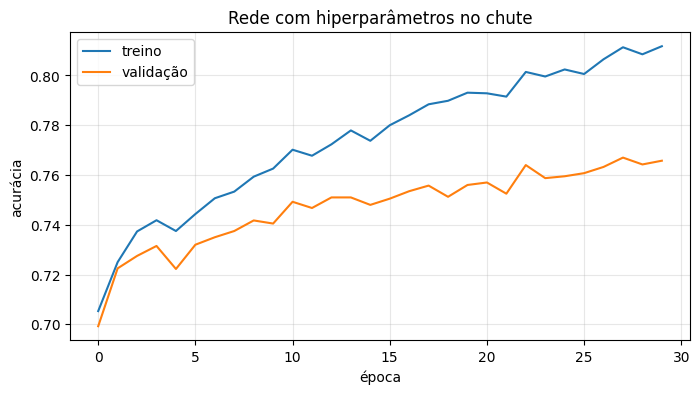

Classe mais comum | acurácia de validação: 0.487
LinearSVC         | acurácia de validação: 0.717
Rede no chute     | acurácia de validação: 0.766


In [ ]:
CHUTE = dict(n_camadas=2, n_neuronios=64, otimizador="Adam", lr=1e-3, tamanho_lote=64)

rede_chute, hist_chute = treinar_rede(**CHUTE)

plt.figure(figsize=(8, 4))
plt.plot(hist_chute["treino"], label="treino")
plt.plot(hist_chute["val"], label="validação")
plt.xlabel("época")
plt.ylabel("acurácia")
plt.title("Rede com hiperparâmetros no chute")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

acc_chute_val = hist_chute["val"][-1]
print(f"Classe mais comum | acurácia de validação: {acc_piso_val:.3f}")
print(f"LinearSVC         | acurácia de validação: {acc_svc_val:.3f}")
print(f"Rede no chute     | acurácia de validação: {acc_chute_val:.3f}")

### 2.5 O que acontece com uma taxa de aprendizado ruim

A taxa de aprendizado define o tamanho do passo que o otimizador dá a cada atualização dos pesos. Para ver o quanto ela pesa no resultado, a rede da seção anterior é treinada mais duas vezes. Arquitetura, otimizador (Adam) e número de épocas são os mesmos; só a taxa muda.

- **0,001:** a taxa da seção anterior, que serve de comparação.
- **0,1 (alta demais):** os passos são grandes demais e o treino não se estabiliza. A rede acaba prevendo sempre a classe mais comum e fica presa no piso.
- **0,00001 (baixa demais):** os passos são pequenos demais. A rede aprende, mas tão devagar que 30 épocas não bastam.

No gráfico, a linha tracejada é o piso da seção 1.3. A mesma rede vai de 77% a 49% de acurácia por causa de um único hiperparâmetro, e ela tem outros quatro escolhidos da mesma forma. É esse o problema que o Optuna resolve na próxima seção.

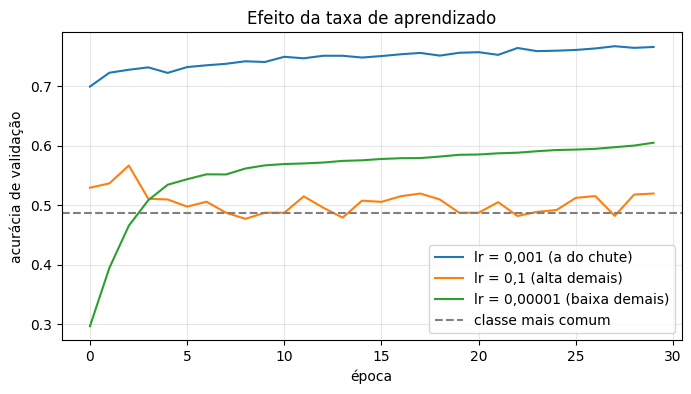

Taxa alta demais: acurácia de validação na última época = 0.520
Taxa baixa demais: acurácia de validação na última época = 0.605


In [ ]:
_, hist_alta = treinar_rede(n_camadas=2, n_neuronios=64, otimizador="Adam", lr=0.1, tamanho_lote=64)
_, hist_baixa = treinar_rede(n_camadas=2, n_neuronios=64, otimizador="Adam", lr=1e-5, tamanho_lote=64)

plt.figure(figsize=(8, 4))
plt.plot(hist_chute["val"], label="lr = 0,001 (a do chute)")
plt.plot(hist_alta["val"], label="lr = 0,1 (alta demais)")
plt.plot(hist_baixa["val"], label="lr = 0,00001 (baixa demais)")
plt.axhline(acc_piso_val, color="gray", linestyle="--", label="classe mais comum")
plt.xlabel("época")
plt.ylabel("acurácia de validação")
plt.title("Efeito da taxa de aprendizado")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for nome, hist in [("alta demais", hist_alta), ("baixa demais", hist_baixa)]:
    print(f"Taxa {nome}: acurácia de validação na última época = {hist['val'][-1]:.3f}")

---
## 3. Optuna: otimização dos hiperparâmetros

### 3.1 A função objetivo

O espaço de busca é declarado dentro da própria função, com as chamadas `trial.suggest_*`. A função devolve a acurácia de validação, que o Optuna vai maximizar.

In [ ]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    n_camadas = trial.suggest_int("n_layers", 1, 4)
    n_neuronios = trial.suggest_int("n_units", 32, 256, step=32)
    otimizador = trial.suggest_categorical("optimizer", ["SGD", "Adam", "RMSprop"])
    tamanho_lote = trial.suggest_categorical("batch_size", [32, 64, 128])

    _, historico = treinar_rede(n_camadas, n_neuronios, otimizador, lr, tamanho_lote, trial=trial)
    return historico["val"][-1]

### 3.2 O estudo

O **estudo** (`study`) é o objeto que conduz a otimização: ele propõe os hiperparâmetros de cada trial, registra os resultados e guarda a melhor configuração encontrada. A célula abaixo cria o estudo e define como ele vai trabalhar.

- **`direction="maximize"`:** a função objetivo devolve a acurácia de validação, então o objetivo é maximizá-la.
- **`TPESampler`:** é a estratégia de busca. Os primeiros trials são sorteados ao acaso; a partir daí, o TPE usa os resultados já obtidos para propor configurações nas regiões mais promissoras do espaço de busca. A semente (`seed`) torna a sequência reproduzível.
- **`MedianPruner`:** é a regra de interrupção. Ao fim de cada época, o trial informa sua acurácia; se ela estiver abaixo da mediana dos trials anteriores naquela mesma época, o trial é abandonado. Os dois parâmetros evitam cortes precipitados: nada é interrompido antes de 5 trials completos (`n_startup_trials`) nem nas 5 primeiras épocas de cada trial (`n_warmup_steps`).
- **`storage` e `load_if_exists`:** o estudo é gravado em um arquivo SQLite. Se o arquivo já existir, o estudo é carregado e continua de onde parou, em vez de começar do zero. É isso que permite executar a otimização antes do seminário e apenas consultar os resultados na hora.

Nenhum desses itens depende do PyTorch. O Optuna só enxerga a função objetivo: recebe um número de volta e decide o que testar em seguida.

In [ ]:
restaurar_estudo()

ARQUIVO = f"sqlite:///{ARQUIVO_DB}"

def novo_pruner():
    return optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)

estudo = optuna.create_study(
    study_name="seminario_mlp",
    storage=ARQUIVO,
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE),
    pruner=novo_pruner(),
)
print(f"Trials já gravados no estudo: {len(estudo.trials)}")

Estudo restaurado do Drive.


[I 2026-10-07 14:40:15,788] Using an existing study with `study_name='seminario_mlp'` instead of creating a new one.


Trials já gravados no estudo: 50


### 3.3 Executar o estudo

Esta célula foi executada **antes** do seminário. Ela completa o estudo até 50 trials (quando o estudo não existe ainda) e leva alguns minutos. Nas execuções seguintes, ela não faz nada.

In [ ]:
N_TRIALS = 50

faltam = max(0, N_TRIALS - len(estudo.trials))
optuna.logging.set_verbosity(optuna.logging.WARNING)
estudo.optimize(
    objective,
    n_trials=faltam,
    callbacks=[lambda estudo, trial: salvar_estudo()],
)
optuna.logging.set_verbosity(optuna.logging.INFO)

salvar_estudo()
print(f"Trials no estudo: {len(estudo.trials)}")

Trials no estudo: 50


### 3.4 Alguns trials ao vivo

Esta é uma célula para ser executada durante o seminário. Ela roda 4 trials novos sobre uma **cópia em memória** do estudo, para mostrar o log e o pruning sem alterar o estudo gravado.

In [ ]:
memoria = optuna.storages.InMemoryStorage()
optuna.copy_study(from_study_name="seminario_mlp", from_storage=ARQUIVO, to_storage=memoria)

estudo_demo = optuna.load_study(
    study_name="seminario_mlp",
    storage=memoria,
    sampler=optuna.samplers.TPESampler(),
    pruner=novo_pruner(),
)
estudo_demo.optimize(objective, n_trials=4)

[I 2026-10-07 14:42:11,128] A new study created in memory with name: seminario_mlp
[I 2026-10-07 14:42:20,075] Trial 50 pruned. 
[I 2026-10-07 14:42:25,958] Trial 51 pruned. 
[I 2026-10-07 14:42:50,051] Trial 52 finished with value: 0.8097500205039978 and parameters: {'lr': 0.00114090093825404, 'n_layers': 3, 'n_units': 256, 'optimizer': 'RMSprop', 'batch_size': 32}. Best is trial 47 with value: 0.8167499899864197.
[I 2026-10-07 14:42:53,126] Trial 53 pruned. 


### 3.5 Resultados

In [ ]:
estados = estudo.trials_dataframe()["state"].value_counts()
print(estados.to_string())
print()
print(f"Melhor acurácia de validação: {estudo.best_value:.3f}")
print("Melhores hiperparâmetros:")
for nome, valor in estudo.best_params.items():
    print(f"  {nome}: {valor}")

state
COMPLETE    25
PRUNED      25

Melhor acurácia de validação: 0.817
Melhores hiperparâmetros:
  lr: 0.0007332113029466402
  n_layers: 4
  n_units: 256
  optimizer: RMSprop
  batch_size: 32


**Histórico da otimização**

Cada ponto do gráfico é um trial que chegou ao fim, com a acurácia de validação que ele obteve. Os trials interrompidos pelo pruning não aparecem, e por isso há espaços vazios no eixo horizontal. A linha mostra o melhor valor encontrado até cada momento.

O que observar: a linha sobe rápido nos primeiros trials e depois avança em degraus cada vez menores. Quando ela fica estável por muitos trials seguidos, é sinal de que continuar a busca nesse espaço tende a render pouco.

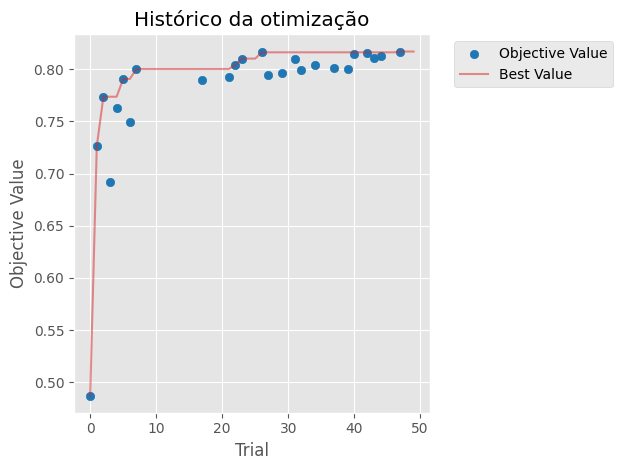

In [ ]:
with plt.rc_context():      # o Optuna troca o estilo dos gráficos; assim a troca fica só aqui
    ax = optuna.visualization.matplotlib.plot_optimization_history(estudo)
    ax.set_title("", loc="left")
    ax.set_title("Histórico da otimização")
    plt.show()

**Importância dos hiperparâmetros**

Este gráfico estima quanto da variação da acurácia entre os trials se deve a cada hiperparâmetro. Os valores somam 1: quanto maior a barra, mais o resultado dependeu daquela escolha.

Neste estudo, a taxa de aprendizado e o número de neurônios respondem por quase toda a variação, enquanto o otimizador e o tamanho do lote pesaram pouco. Isso confirma o que a seção 2.5 mostrou com um único exemplo.

Uma ressalva: a importância vale para as faixas de valores testadas aqui. Um hiperparâmetro com barra pequena não é irrelevante em geral; ele apenas fez pouca diferença dentro deste espaço de busca.

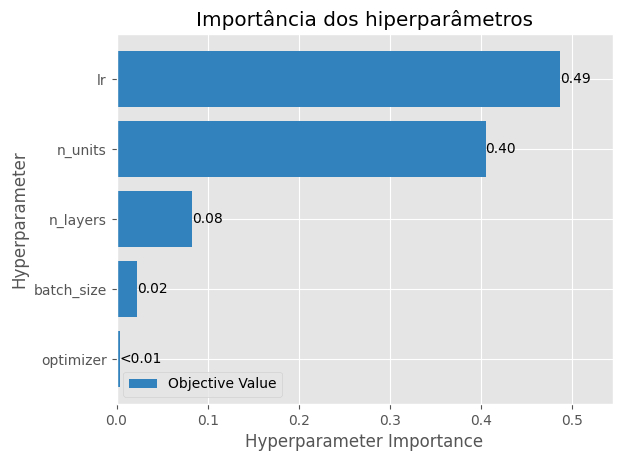

In [ ]:
with plt.rc_context():
    ax = optuna.visualization.matplotlib.plot_param_importances(estudo)
    ax.set_title("", loc="left")
    ax.set_title("Importância dos hiperparâmetros")
    plt.show()

---
## 4. Síntese: comparação no conjunto de teste

Os modelos são avaliados em dados que nenhum deles viu. A rede otimizada é treinada de novo com os melhores hiperparâmetros.

In [ ]:
p = estudo.best_params
rede_otimizada, _ = treinar_rede(
    n_camadas=p["n_layers"],
    n_neuronios=p["n_units"],
    otimizador=p["optimizer"],
    lr=p["lr"],
    tamanho_lote=p["batch_size"],
)

def prever(rede, X_t):
    rede.eval()
    with torch.no_grad():
        return rede(X_t).argmax(dim=1).numpy()

previsoes = {
    "Classe mais comum (piso)": piso.predict(X_teste),
    "LinearSVC": modelo_svc.predict(X_teste),
    "Rede sem otimização": prever(rede_chute, Xt_teste),
    "Rede otimizada": prever(rede_otimizada, Xt_teste),
}

tabela = pd.DataFrame({
    "Acurácia (teste)": {nome: accuracy_score(y_teste, prev) for nome, prev in previsoes.items()},
})
tabela["Acertos em 4.000"] = (tabela["Acurácia (teste)"] * len(y_teste)).round().astype(int)
tabela.round(3)

,Acurácia (teste),Acertos em 4.000
Classe mais comum (piso),0.488,1951
LinearSVC,0.712,2846
Rede sem otimização,0.781,3123
Rede otimizada,0.815,3260


### Matriz de confusão da rede otimizada

A acurácia sozinha esconde o que acontece nas classes raras. A matriz mostra onde estão os erros.

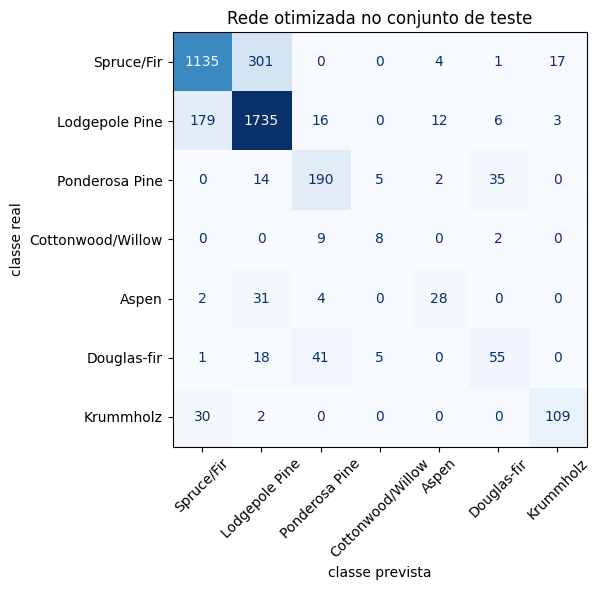

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes["Rede otimizada"],
    display_labels=CLASSES, xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe real")
ax.set_title("Rede otimizada no conjunto de teste")
plt.tight_layout()
plt.show()